# Historical simulation versus the four-stock SDE-GAN

Compare `benchmarks/historical.py` with the saved original SDE-GAN and the
temporal-penalty experiments (weights 10 and 30). The questions are whether the
model reproduces marginal returns, cross-stock and temporal dependence, and
20-session portfolio risk better than replaying historical training windows.

Use the **`sandbox/.venv` Python kernel** and run all cells from the repository
root or this directory. Existing inspection samples are reused; a checkpoint
without samples is sampled once in memory using a fixed seed. Nothing is
trained or written to the experiment directories. Results and figures are
stored in this notebook's outputs.

This is a **validation review**, not a final test evaluation. Validation was
already used for checkpoint selection, so these results are not an unbiased
estimate of performance on new data. Test data are opened only if
`EVALUATE_TEST = True`, after the experiment choices have been frozen.


In [1]:
from pathlib import Path
from itertools import combinations
import json
import os
import sys

os.environ.setdefault("JAX_PLATFORMS", "cpu")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "benchmarks/historical.py").is_file())
experiment_dir = root / "sandbox/4stocks_experiment"
data_dir = experiment_dir / "data"
runs_dir = experiment_dir / "results/sde_gan"
for path in [root, experiment_dir]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from benchmarks.historical import (
    HistoricalSimulation, HistoricalSimulationConfig, _empirical_var, _empirical_es,
)

RUN_GROUPS = {"original": "", "temporal 10": "temporal_penalty",
              "temporal 30": "temporal_penalty_30"}
RUN_SEEDS = [0, 1, 2]  # Report every available seed; never select by validation plots.
PLOT_SEED = 0
N_PATHS = 1000
SAMPLE_SEED = 100
CONFIDENCE_LEVELS = (0.95, 0.99)
EVALUATE_TEST = False

preprocessing = json.loads((data_dir / "preprocessing.json").read_text())
STOCKS = preprocessing["stock_order"]
HORIZON = preprocessing["window_length"]
WEIGHTS = np.full(len(STOCKS), 1 / len(STOCKS))
assert HORIZON == 20 and len(STOCKS) == 4 and preprocessing["transform"] == "log1p"
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
print(f"Python: {sys.executable}\nHorizon: {HORIZON} sessions; weights: {WEIGHTS}")


Python: /Users/pasha/Desktop/master/master_thesis/sandbox/.venv/bin/python
Horizon: 20 sessions; weights: [0.25 0.25 0.25 0.25]


## Comparison contract

- All inputs are **simple daily returns in fractions**, in the saved stock order.
  Generated standardized log returns are inverted using their paired training scaler.
- Each portfolio starts at equal 25% weights and rebalances every session:
  $R = \prod_{t=1}^{20}(1 + \sum_i w_i r_{t,i}) - 1$, with loss $L=-R$.
  We do not compound weighted individual log returns.
- Historical simulation uses **all complete contiguous training blocks**, stride
  one, without deleting missing rows or bridging gaps. It is fitted only on
  training data and remains fixed during validation, matching the unconditional
  generator's fixed scenario distribution. No validation observations enter
  either forecast distribution during this notebook.
- VaR uses the first loss whose empirical CDF reaches the confidence level.
  ES averages exactly the worst $1-c$ probability mass, including a fractional
  boundary observation. Both methods reuse the implementations in
  `historical.py`; old CSVs using interpolated quantiles are not mixed in.
- Historical blocks and validation targets overlap. Daily summaries pool
  windows, repeating some dates. Scenario counts and tail masses are **not
  independent sample sizes**. More generated paths reduce Monte Carlo noise,
  not uncertainty about the fitted market distribution.


In [2]:
splits = ["train", "validation"] + (["test"] if EVALUATE_TEST else [])
returns = {
    split: pd.read_csv(data_dir / f"{split}_returns.csv", parse_dates=["Date"])
    for split in splits
}
window_dates = pd.read_csv(data_dir / "window_dates.csv",
                           parse_dates=["start_date", "end_date"])


def to_simple(paths: np.ndarray, metadata: dict) -> np.ndarray:
    """Invert the paired scaler into finite simple returns, preserving path axes."""
    if metadata != preprocessing:
        raise ValueError("Checkpoint and prepared-data preprocessing differ")
    if paths.ndim != 3 or paths.shape[1:] != (HORIZON, len(STOCKS)):
        raise ValueError("Unexpected sample shape")
    with np.errstate(over="raise", invalid="raise"):
        simple = np.expm1(paths.astype(np.float64) * np.asarray(metadata["training_std"])
                          + np.asarray(metadata["training_mean"]))
    if not np.isfinite(simple).all():
        raise ValueError("Nonfinite inverse-transformed samples")
    return simple


def observed_windows(split: str) -> np.ndarray:
    """Read retained original CSV blocks without removing or filling missing rows."""
    frame = returns[split].set_index("Date").loc[:, STOCKS]
    dates = window_dates.loc[window_dates.split.eq(split)].sort_values("window_index")
    paths = np.stack([frame.loc[r.start_date:r.end_date].to_numpy()
                      for r in dates.itertuples()])
    if paths.shape != (preprocessing["splits"][split]["retained"], HORIZON, len(STOCKS)):
        raise ValueError(f"Unexpected {split} window shape")
    assert np.isfinite(paths).all()
    with np.load(data_dir / "prepared_windows.npz", allow_pickle=False) as prepared:
        np.testing.assert_allclose(to_simple(prepared[f"{split}_windows"], preprocessing),
                                   paths, rtol=1e-6, atol=1e-7)
    return paths


observed = {split: observed_windows(split) for split in splits}
for previous, following in zip(splits, splits[1:]):
    assert returns[previous].Date.max() < returns[following].Date.min()
display(pd.DataFrame([{
    "split": split, "first_date": returns[split].Date.min(),
    "last_date": returns[split].Date.max(), "raw_sessions": len(returns[split]),
    "complete_windows": len(observed[split]),
    "excluded_windows": len(returns[split]) - HORIZON + 1 - len(observed[split]),
} for split in splits]).set_index("split"))


,first_date,last_date,raw_sessions,complete_windows,excluded_windows
split,,,,,
train,2005-01-03,2020-03-05,3811,1679,2113
validation,2020-03-06,2023-06-07,817,709,89


## Run the historical benchmark

`historical.py` is an API: it does not save results itself. Run its public
`fit`, `summarize`, and `backtest` methods below. The date and compounding checks
ensure that the benchmark scenarios exactly match the windows seen by the GAN.
The historical distribution is used in full, rather than introducing randomness
by resampling it to match the generator's path count.


In [3]:
config = HistoricalSimulationConfig(
    assets=tuple(STOCKS), weights=dict(zip(STOCKS, WEIGHTS)),
    return_type="simple", horizon_sessions=HORIZON, rebalance="daily",
    confidence_levels=CONFIDENCE_LEVELS, estimation="fixed", min_scenarios=100,
)
historical = HistoricalSimulation(config).fit(returns["train"])
historical_summary = historical.summarize()


def terminal_returns(paths: np.ndarray) -> np.ndarray:
    """Compound the daily-rebalanced portfolio in original return units."""
    result = np.prod(1 + paths @ WEIGHTS, axis=1) - 1
    assert np.isfinite(result).all()
    return result


train_dates = window_dates.loc[window_dates.split.eq("train")].sort_values("window_index")
np.testing.assert_array_equal(historical_summary.scenarios.scenario_start,
                              train_dates.start_date)
np.testing.assert_array_equal(historical_summary.scenarios.scenario_end,
                              train_dates.end_date)
np.testing.assert_allclose(historical_summary.scenarios.portfolio_return,
                          terminal_returns(observed["train"]), rtol=0, atol=1e-14)
fixture = np.zeros((1, HORIZON, len(STOCKS)))
fixture[0, 0, 0], fixture[0, 1, 1] = 0.10, -0.10
np.testing.assert_allclose(terminal_returns(fixture), [1.025 * 0.975 - 1])
display(historical_summary.risk)
display(pd.Series({key: historical_summary.metadata[key] for key in
                   ["quantile_convention", "es_convention", "missing_block_policy"]}))


,method,confidence,horizon_sessions,rebalance,var,es,tail_mass_observations,small_tail_sample,overlapping_scenarios,history_start,history_end,n_history_sessions,n_candidate_blocks,n_excluded_blocks,n_scenarios,portfolio_mean_return,portfolio_std_return
0,historical_simulation,0.95,20,daily,0.090078,0.126370,83.95,False,True,2005-01-03,2020-03-05,3811,3792,2113,1679,0.009629,0.062023
1,historical_simulation,0.99,20,daily,0.139635,0.196493,16.79,True,True,2005-01-03,2020-03-05,3811,3792,2113,1679,0.009629,0.062023


quantile_convention               inverse empirical CDF; no interpolation
es_convention           mean of worst 1-confidence mass with fractiona...
missing_block_policy    exclude any block with a missing selected retu...
dtype: object

## Load each available model run

Use the coarse (`dt=0.25`) samples saved by `inspect_sde_gan.ipynb`. If a run has
no inspection samples, restore its selected checkpoint and sample with the same
fixed count and seed. Missing runs appear in the inventory instead of being
silently treated as completed experiments. Seeds are kept separate throughout.

The old inspection manifests record preprocessing, count, seed and solver step,
but not a checkpoint hash or selected step. Those checks establish compatible
samples; they cannot prove that a cache belongs to a subsequently overwritten
checkpoint. `recorded_step` below comes from the current run metadata. Regenerate
inspection samples if a checkpoint has been replaced.


In [4]:
generated, fine_generated, inventory, solver_tables = {}, {}, [], []
for group, folder in RUN_GROUPS.items():
    group_dir = runs_dir / folder
    inspection_dir = group_dir / "inspection"
    manifest_path = inspection_dir / "inspection.json"
    manifest = json.loads(manifest_path.read_text()) if manifest_path.is_file() else None
    for seed in RUN_SEEDS:
        run_dir = group_dir / f"seed_{seed}"
        name = f"{group} / seed {seed}"
        if not (run_dir / "generator.eqx").is_file():
            inventory.append({"dataset": name, "group": group, "seed": seed,
                              "status": "checkpoint unavailable"})
            continue
        metadata = json.loads((run_dir / "preprocessing.json").read_text())
        if metadata != preprocessing:
            raise ValueError(f"Preprocessing mismatch: {name}")
        run = json.loads((run_dir / "run.json").read_text())
        settings = json.loads((run_dir / "config.json").read_text())
        assert run["fit_seed"] == seed and np.isclose(settings["generator_dt"], 0.25)
        cache = inspection_dir / f"samples_seed_{seed}.npz"
        if cache.is_file():
            if (manifest is None or manifest["preprocessing"] != metadata
                    or manifest["stock_order"] != STOCKS or manifest["horizon"] != HORIZON
                    or manifest["n_paths"] != N_PATHS or manifest["sample_seed"] != SAMPLE_SEED
                    or seed not in manifest["run_seeds"]
                    or not np.isclose(manifest["coarse_dt"], settings["generator_dt"])):
                raise ValueError(f"Incompatible inspection cache: {cache}")
            with np.load(cache, allow_pickle=False) as samples:
                standardized = samples["coarse_standardized_log"]
                fine_generated[name] = to_simple(samples["fine_standardized_log"], metadata)
            source = str(cache.relative_to(root))
        else:
            from sde_gan import SDEGAN
            print(f"Sampling selected checkpoint: {name}", flush=True)
            standardized = SDEGAN.load(run_dir).sample(N_PATHS, SAMPLE_SEED)
            source = f"checkpoint sampled in memory: {run_dir.relative_to(root)}"
        assert standardized.shape == (N_PATHS, HORIZON, len(STOCKS))
        generated[name] = to_simple(standardized, metadata)
        inventory.append({
            "dataset": name, "group": group, "seed": seed, "status": "included",
            "recorded_step": run["selected_step"], "validation_mmd2": run["validation_score"],
            "temporal_weight": settings.get("temporal_penalty_weight", 0),
            "paths": len(standardized), "source": source,
        })
    sensitivity_path = inspection_dir / "solver_sensitivity.csv"
    if sensitivity_path.is_file():
        solver_tables.append(pd.read_csv(sensitivity_path).assign(group=group))

inventory = pd.DataFrame(inventory).set_index("dataset")
if not generated:
    raise ValueError("No saved model runs are available for comparison")
display(inventory.drop(columns="source"))
with pd.option_context("display.max_colwidth", None):
    display(inventory.loc[inventory.status.eq("included"), ["source"]])
datasets = {"historical simulation": observed["train"],
            "validation (observed)": observed["validation"], **generated}
representatives = [f"{group} / seed {PLOT_SEED}" for group in RUN_GROUPS
                   if f"{group} / seed {PLOT_SEED}" in generated]
plot_names = ["historical simulation", "validation (observed)", *representatives]


Sampling selected checkpoint: temporal 30 / seed 0


,group,seed,status,recorded_step,validation_mmd2,temporal_weight,paths
dataset,,,,,,,
original / seed 0,original,0,included,1600.0,0.018549,0.0,1000.0
original / seed 1,original,1,included,2000.0,0.018292,0.0,1000.0
original / seed 2,original,2,included,2000.0,0.019369,0.0,1000.0
temporal 10 / seed 0,temporal 10,0,included,1600.0,0.023125,10.0,1000.0
temporal 10 / seed 1,temporal 10,1,included,1400.0,0.025744,10.0,1000.0
temporal 10 / seed 2,temporal 10,2,included,1600.0,0.016164,10.0,1000.0
temporal 30 / seed 0,temporal 30,0,included,200.0,0.059402,30.0,1000.0
temporal 30 / seed 1,temporal 30,1,checkpoint unavailable,NaN,NaN,NaN,NaN
temporal 30 / seed 2,temporal 30,2,checkpoint unavailable,NaN,NaN,NaN,NaN


,source
dataset,
original / seed 0,sandbox/4stocks_experiment/results/sde_gan/inspection/samples_seed_0.npz
original / seed 1,sandbox/4stocks_experiment/results/sde_gan/inspection/samples_seed_1.npz
original / seed 2,sandbox/4stocks_experiment/results/sde_gan/inspection/samples_seed_2.npz
temporal 10 / seed 0,sandbox/4stocks_experiment/results/sde_gan/temporal_penalty/inspection/samples_seed_0.npz
temporal 10 / seed 1,sandbox/4stocks_experiment/results/sde_gan/temporal_penalty/inspection/samples_seed_1.npz
temporal 10 / seed 2,sandbox/4stocks_experiment/results/sde_gan/temporal_penalty/inspection/samples_seed_2.npz
temporal 30 / seed 0,checkpoint sampled in memory: sandbox/4stocks_experiment/results/sde_gan/temporal_penalty_30/seed_0


## Marginal returns and exact zeros

Means, standard deviations and quantiles are reported in percent per session;
`zero_pct` is a percentage of observations. Pooling historical windows describes
the empirical distribution actually used for training, not equally weighted
unique market dates. A continuous generator does not explicitly model a point
mass at zero. Compare that discrepancy separately from tail or volatility fit.
Tables include all seeds; figures use the preselected seed 0 for readability.


mean_pct  std_pct  q01_pct  q05_pct  \
dataset               stock                                                    
historical simulation KONGSBERG GRUPPEN    0.0747   1.8093  -5.1876  -2.6415   
                      FRONTLINE           -0.0450   3.6416  -8.9062  -5.4217   
                      WILH Wilhelmsen B    0.0295   1.7935  -4.5045  -2.7933   
                      TOMRA SYSTEMS        0.1325   1.8932  -4.5944  -2.7228   
validation (observed) KONGSBERG GRUPPEN    0.2253   1.9881  -4.4138  -2.8517   
                      FRONTLINE            0.2055   3.5967  -8.7812  -5.1864   
                      WILH Wilhelmsen B    0.1360   2.3871  -5.3097  -3.4188   
                      TOMRA SYSTEMS        0.0453   2.3924  -6.5920  -3.8283   
original / seed 0     KONGSBERG GRUPPEN    0.1078   1.8580  -3.9011  -2.5001   
                      FRONTLINE            0.2164   4.0900  -8.0876  -5.2960   
                      WILH Wilhelmsen B   -0.0197   1.9439  -4.9494  -2.9590   
                      TOMRA SYSTEMS        0.0080   1.3150  -3.0812  -2.0804   
original / seed 1     KONGSBERG GRUPPEN    0.0244   1.6731  -4.1844  -2.7568   
                      FRONTLINE           -0.1368   3.2397  -7.4768  -5.3199   
                      WILH Wilhelmsen B    0.1194   1.9740  -4.1959  -2.9751   
                      TOMRA SYSTEMS        0.3361   2.0251  -4.1460  -2.7076   
original / seed 2     KONGSBERG GRUPPEN    0.0274   1.8643  -4.3164  -2.9296   
                      FRONTLINE            0.3085   3.2312  -7.1603  -4.7558   
                      WILH Wilhelmsen B   -0.1332   1.3863  -3.4439  -2.3609   
                      TOMRA SYSTEMS        0.3195   1.7673  -3.6711  -2.4891   
temporal 10 / seed 0  KONGSBERG GRUPPEN    0.0856   1.3892  -3.3684  -2.1963   
                      FRONTLINE           -0.1732   2.6588  -6.9151  -4.5509   
                      WILH Wilhelmsen B    0.0530   1.7390  -3.9808  -2.6770   
                      TOMRA SYSTEMS        0.1933   1.6093  -3.5219  -2.3396   
temporal 10 / seed 1  KONGSBERG GRUPPEN    0.1587   1.2243  -2.7987  -1.8375   
                      FRONTLINE            0.2526   3.4243  -7.6411  -5.1531   
                      WILH Wilhelmsen B    0.0683   1.2816  -2.9827  -2.0198   
                      TOMRA SYSTEMS        0.1124   1.4658  -3.2483  -2.2194   
temporal 10 / seed 2  KONGSBERG GRUPPEN   -0.0061   1.7723  -4.8618  -2.9562   
                      FRONTLINE           -0.0681   2.8618  -7.3623  -4.6719   
                      WILH Wilhelmsen B    0.2063   1.9639  -3.9448  -2.7656   
                      TOMRA SYSTEMS        0.1059   1.3743  -3.1708  -2.1083   
temporal 30 / seed 0  KONGSBERG GRUPPEN    0.0910   0.8334  -1.7204  -1.1042   
                      FRONTLINE           -0.3926   1.8429  -5.8213  -3.4485   
                      WILH Wilhelmsen B    0.1299   1.3209  -2.9762  -1.8631   
                      TOMRA SYSTEMS       -0.3136   0.5605  -1.8491  -1.2330   

                                         q50_pct  q95_pct  q99_pct  zero_pct  
dataset               stock                                                   
historical simulation KONGSBERG GRUPPEN   0.0000   2.7668   5.3030   12.2990  
                      FRONTLINE          -0.1713   5.4304  11.2971    3.3175  
                      WILH Wilhelmsen B   0.0000   3.0030   5.0000   12.8172  
                      TOMRA SYSTEMS       0.0000   3.1662   5.8366    9.7528  
validation (observed) KONGSBERG GRUPPEN   0.1799   3.3292   5.2459    2.5458  
                      FRONTLINE           0.1305   6.0195   9.4033    0.6417  
                      WILH Wilhelmsen B   0.0000   3.8023   7.6271   11.5303  
                      TOMRA SYSTEMS       0.1171   3.8653   6.5506    0.1410  
original / seed 0     KONGSBERG GRUPPEN  -0.1012   3.4263   5.5778    0.0000  
                      FRONTLINE          -0.3035   7.5055  13.5611    0.0000  
                      WILH Wilhelmsen B  -0.0848   3

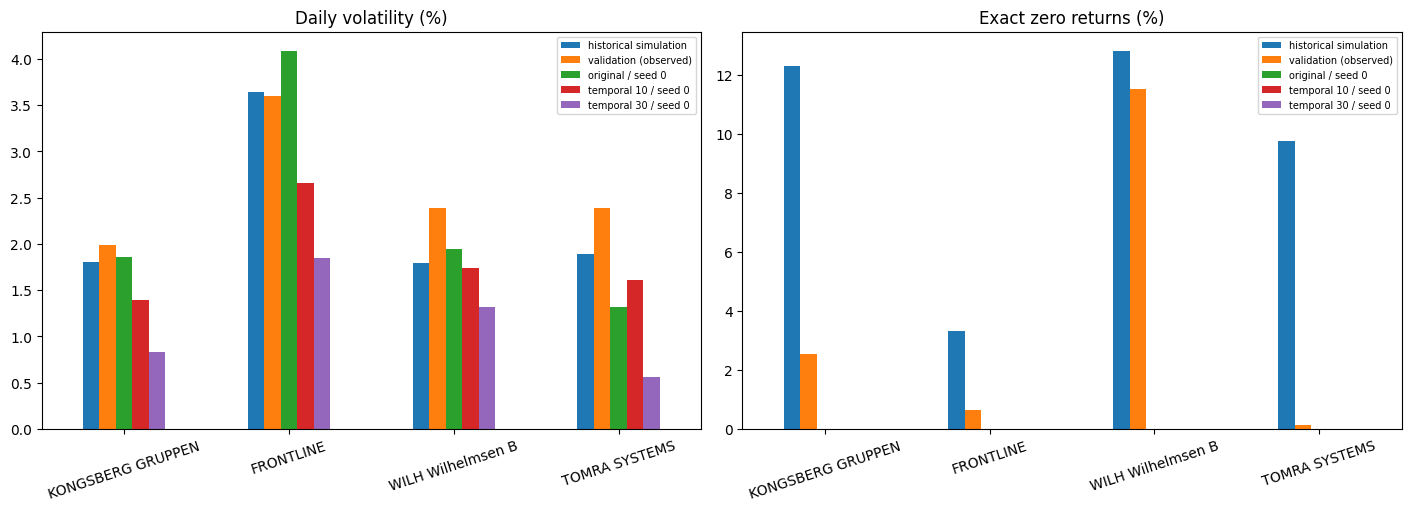

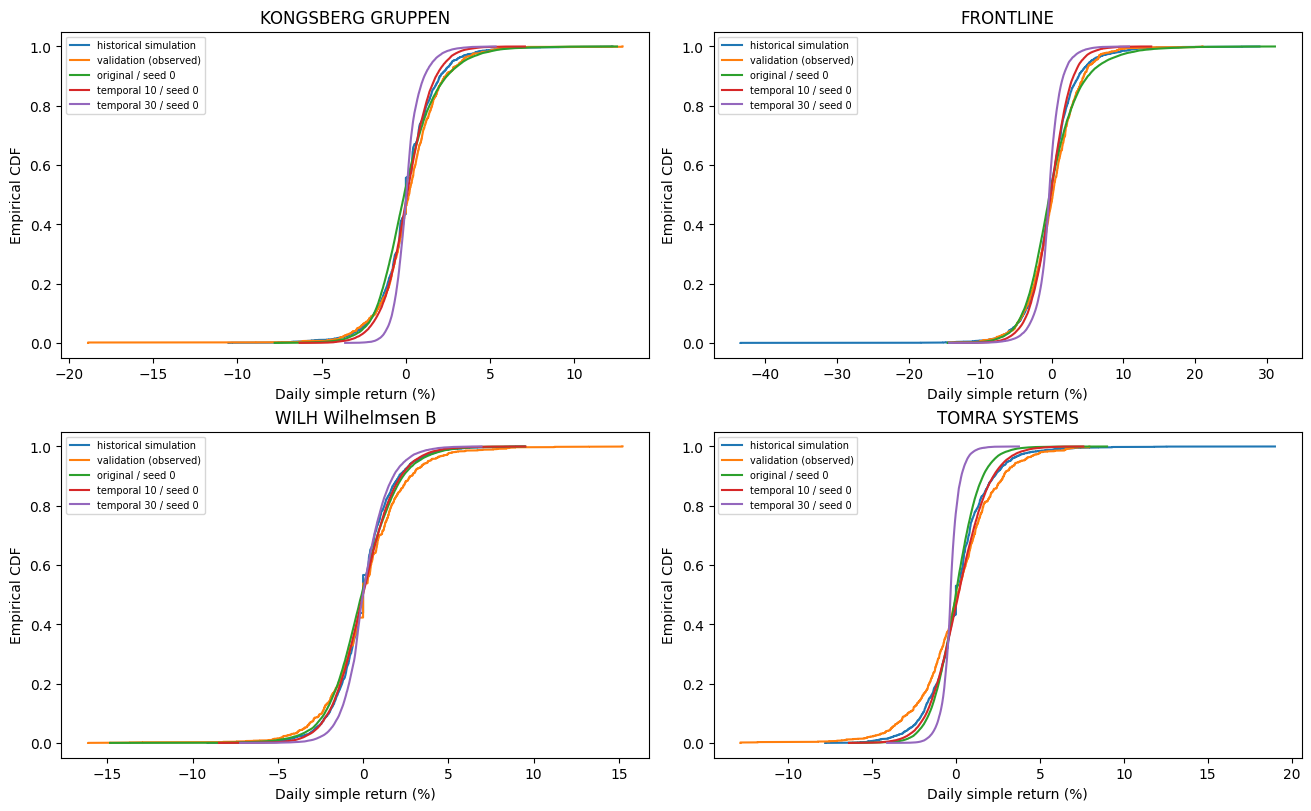

In [5]:
flat = {name: pd.DataFrame(paths.reshape(-1, len(STOCKS)), columns=STOCKS)
        for name, paths in datasets.items()}
marginals = pd.concat({name: pd.DataFrame({
    "mean_pct": frame.mean() * 100, "std_pct": frame.std(ddof=1) * 100,
    "q01_pct": frame.quantile(0.01) * 100, "q05_pct": frame.quantile(0.05) * 100,
    "q50_pct": frame.quantile(0.50) * 100, "q95_pct": frame.quantile(0.95) * 100,
    "q99_pct": frame.quantile(0.99) * 100, "zero_pct": frame.eq(0).mean() * 100,
}) for name, frame in flat.items()}, names=["dataset", "stock"])
display(marginals.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for column, title, ax in zip(["std_pct", "zero_pct"],
                            ["Daily volatility (%)", "Exact zero returns (%)"], axes):
    marginals[column].unstack("stock").loc[plot_names].T.plot.bar(ax=ax)
    ax.set(title=title, xlabel="")
    ax.tick_params(axis="x", rotation=18)
    ax.legend(fontsize=7)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for stock, ax in zip(STOCKS, axes.flat):
    for name in plot_names:
        values = np.sort(flat[name][stock].to_numpy()) * 100
        ax.plot(values, np.arange(1, len(values) + 1) / len(values), label=name)
    ax.set(title=stock, xlabel="Daily simple return (%)", ylabel="Empirical CDF")
    ax.legend(fontsize=7)
plt.show()
plt.close(fig)


## Cross-stock dependence and joint downside events

Pearson and average-rank Spearman correlations measure contemporaneous
dependence. Joint downside frequencies use each stock's **training-window 5%
quantile**, held fixed for every dataset. Report the number of pooled daily
observations alongside the event count. These are finite-threshold co-loss
frequencies, not estimates of asymptotic tail dependence or independent counts.


pearson  spearman
dataset               pair                                                    
historical simulation KONGSBERG GRUPPEN / FRONTLINE            0.112     0.101
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B    0.098     0.119
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.191     0.160
                      FRONTLINE / WILH Wilhelmsen B            0.067     0.085
                      FRONTLINE / TOMRA SYSTEMS                0.137     0.131
                      WILH Wilhelmsen B / TOMRA SYSTEMS        0.134     0.114
validation (observed) KONGSBERG GRUPPEN / FRONTLINE            0.147     0.168
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B    0.207     0.182
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.143     0.172
                      FRONTLINE / WILH Wilhelmsen B            0.117     0.109
                      FRONTLINE / TOMRA SYSTEMS                0.025    -0.005
                      WILH Wilhelmsen B / TOMRA SYSTEMS        0.186     0.157
original / seed 0     KONGSBERG GRUPPEN / FRONTLINE            0.182     0.208
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B    0.250     0.292
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.480     0.476
                      FRONTLINE / WILH Wilhelmsen B           -0.065     0.000
                      FRONTLINE / TOMRA SYSTEMS                0.460     0.443
                      WILH Wilhelmsen B / TOMRA SYSTEMS        0.532     0.523
original / seed 1     KONGSBERG GRUPPEN / FRONTLINE            0.095     0.113
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B    0.136     0.150
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.142     0.159
                      FRONTLINE / WILH Wilhelmsen B            0.001    -0.048
                      FRONTLINE / TOMRA SYSTEMS                0.164     0.138
                      WILH Wilhelmsen B / TOMRA SYSTEMS        0.343     0.355
original / seed 2     KONGSBERG GRUPPEN / FRONTLINE           -0.025    -0.029
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B    0.493     0.515
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.080     0.055
                      FRONTLINE / WILH Wilhelmsen B            0.172     0.150
                      FRONTLINE / TOMRA SYSTEMS                0.074     0.086
                      WILH Wilhelmsen B / TOMRA SYSTEMS       -0.288    -0.275
temporal 10 / seed 0  KONGSBERG GRUPPEN / FRONTLINE           -0.111    -0.103
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B   -0.030    -0.012
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.389     0.379
                      FRONTLINE / WILH Wilhelmsen B            0.022     0.016
                      FRONTLINE / TOMRA SYSTEMS                0.441     0.432
                      WILH Wilhelmsen B / TOMRA SYSTEMS        0.358     0.350
temporal 10 / seed 1  KONGSBERG GRUPPEN / FRONTLINE            0.571     0.560
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B    0.302     0.288
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS        0.656     0.627
                      FRONTLINE / WILH Wilhelmsen B            0.228     0.229
                      FRONTLINE / TOMRA SYSTEMS               -0.104    -0.093
                      WILH Wilhelmsen B / TOMRA SYSTEMS        0.450     0.433
temporal 10 / seed 2  KONGSBERG GRUPPEN / FRONTLINE            0.001    -0.011
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B   -0.026    -0.007
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS       -0.023    -0.019
                      FRONTLINE / WILH Wilhelmsen B           -0.069    -0.059
                      FRONTLINE / TOMRA SYSTEMS                0.590     0.592
                      WILH Wilhelmsen B / TOMRA SYSTEMS       -0.060    -0.057
temporal 30 / seed 0  KONGSBERG GRUPPEN / FRONTLINE           -0.452    -0.427
                      KONGSBERG 

KONGSBERG GRUPPEN   -2.641509
FRONTLINE           -5.421687
WILH Wilhelmsen B   -2.793296
TOMRA SYSTEMS       -2.722772
Name: Training downside threshold (%), dtype: float64

count  \
dataset               stocks                                                      
historical simulation KONGSBERG GRUPPEN / FRONTLINE                         225   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                 173   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                     351   
                      FRONTLINE / WILH Wilhelmsen B                         189   
                      FRONTLINE / TOMRA SYSTEMS                             252   
                      WILH Wilhelmsen B / TOMRA SYSTEMS                     195   
                      KONGSBERG GRUPPEN / FRONTLINE / WILH Wilhelmsen...     44   
validation (observed) KONGSBERG GRUPPEN / FRONTLINE                         121   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                 208   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                     139   
                      FRONTLINE / WILH Wilhelmsen B                         109   
                      FRONTLINE / TOMRA SYSTEMS                              41   
                      WILH Wilhelmsen B / TOMRA SYSTEMS                     228   
                      KONGSBERG GRUPPEN / FRONTLINE / WILH Wilhelmsen...     21   
original / seed 0     KONGSBERG GRUPPEN / FRONTLINE                          74   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                 176   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                     136   
                      FRONTLINE / WILH Wilhelmsen B                          67   
                      FRONTLINE / TOMRA SYSTEMS                              89   
                      WILH Wilhelmsen B / TOMRA SYSTEMS                     156   
                      KONGSBERG GRUPPEN / FRONTLINE / WILH Wilhelmsen...      4   
original / seed 1     KONGSBERG GRUPPEN / FRONTLINE                          86   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                  86   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                     152   
                      FRONTLINE / WILH Wilhelmsen B                          16   
                      FRONTLINE / TOMRA SYSTEMS                              42   
                      WILH Wilhelmsen B / TOMRA SYSTEMS                     279   
                      KONGSBERG GRUPPEN / FRONTLINE / WILH Wilhelmsen...      1   
original / seed 2     KONGSBERG GRUPPEN / FRONTLINE                          90   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                 198   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                      95   
                      FRONTLINE / WILH Wilhelmsen B                          45   
                      FRONTLINE / TOMRA SYSTEMS                              40   
                      WILH Wilhelmsen B / TOMRA SYSTEMS                       6   
                      KONGSBERG GRUPPEN / FRONTLINE / WILH Wilhelmsen...      1   
temporal 10 / seed 0  KONGSBERG GRUPPEN / FRONTLINE                          14   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                  35   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                      74   
                      FRONTLINE / WILH Wilhelmsen B                          65   
                      FRONTLINE / TOMRA SYSTEMS                             136   
                      WILH Wilhelmsen B / TOMRA SYSTEMS                     158   
                      KONGSBERG GRUPPEN / FRONTLINE / WILH Wilhelmsen...      0   
temporal 10 / seed 1  KONGSBERG GRUPPEN / FRONTLINE                         126   
                      KONGSBERG GRUPPEN / WILH Wilhelmsen B                  22   
                      KONGSBERG GRUPPEN / TOMRA SYSTEMS                      98   
                      FRONTLINE / WILH Wilhelmsen B                          41   
                      FRONTLINE / TOMRA SYSTEMS                              22   
       

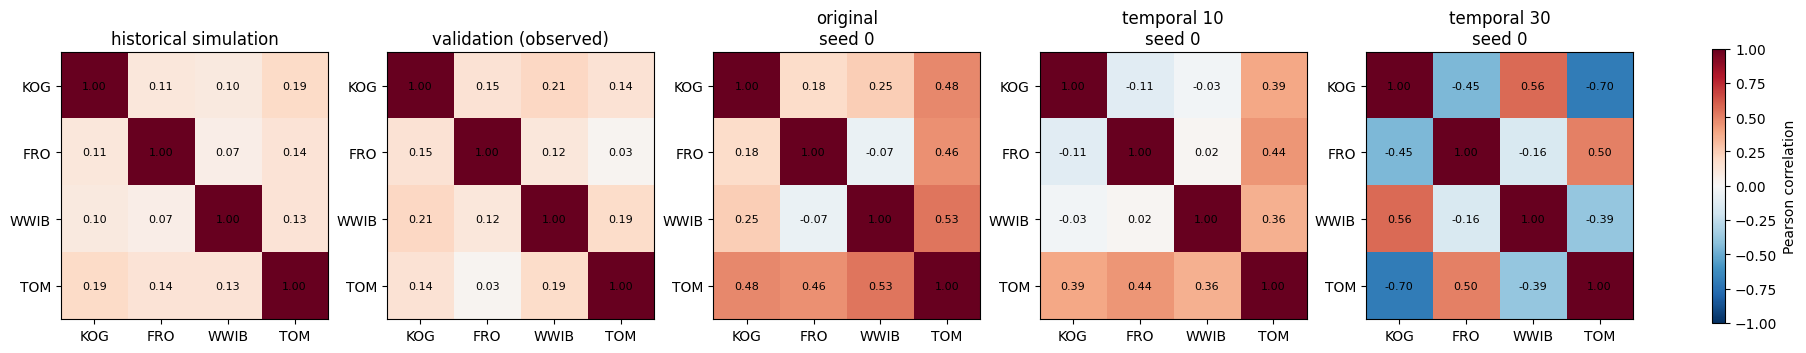

In [6]:
pearson = {name: frame.corr() for name, frame in flat.items()}
spearman = {name: frame.corr(method="spearman") for name, frame in flat.items()}
pairs = list(combinations(range(len(STOCKS)), 2))
dependence = pd.DataFrame([
    {"dataset": name, "pair": f"{STOCKS[i]} / {STOCKS[j]}",
     "pearson": pearson[name].iloc[i, j], "spearman": spearman[name].iloc[i, j]}
    for name in datasets for i, j in pairs
]).set_index(["dataset", "pair"])
display(dependence.round(3))

thresholds = flat["historical simulation"].quantile(0.05).to_numpy()
display(pd.Series(thresholds * 100, index=STOCKS, name="Training downside threshold (%)"))
joint_downside = []
for name, frame in flat.items():
    events = frame.to_numpy() <= thresholds
    for group in [*pairs, tuple(range(len(STOCKS)))]:
        count = int(events[:, group].all(axis=1).sum())
        joint_downside.append({"dataset": name, "stocks": " / ".join(STOCKS[i] for i in group),
                               "count": count, "pooled_observations": len(frame),
                               "frequency_pct": 100 * count / len(frame)})
joint_downside = pd.DataFrame(joint_downside).set_index(["dataset", "stocks"])
display(joint_downside.round(3))

fig, axes = plt.subplots(1, len(plot_names), figsize=(18, 4), constrained_layout=True)
for name, ax in zip(plot_names, axes):
    image = ax.imshow(pearson[name], vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=name.replace(" / ", "\n"), xticks=range(4), yticks=range(4),
           xticklabels=["KOG", "FRO", "WWIB", "TOM"],
           yticklabels=["KOG", "FRO", "WWIB", "TOM"])
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{pearson[name].iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.7, label="Pearson correlation")
plt.show()
plt.close(fig)


## Temporal dependence

Correlate aligned pairs at lags 1–5 **within each path**, pooling pairs without
ever joining the end of one path to the next. Signed-return correlations assess
return persistence; absolute-return correlations assess persistence of return
magnitudes. Check both: matching signed returns alone does not establish that
volatility clustering is reproduced. Constant inputs yield unavailable
correlations, not artificially perfect agreement.


KONGSBERG GRUPPEN  FRONTLINE  \
metric         dataset                                               
signed lag 1   historical simulation             -0.096      0.029   
               validation (observed)              0.020     -0.072   
               original / seed 0                  0.786      0.867   
               original / seed 1                  0.800      0.861   
               original / seed 2                  0.851      0.749   
               temporal 10 / seed 0               0.606      0.561   
               temporal 10 / seed 1               0.474      0.673   
               temporal 10 / seed 2               0.632      0.597   
               temporal 30 / seed 0               0.863      0.813   
absolute lag 1 historical simulation              0.207      0.288   
               validation (observed)              0.147      0.113   
               original / seed 0                  0.670      0.787   
               original / seed 1                  0.632      0.741   
               original / seed 2                  0.689      0.589   
               temporal 10 / seed 0               0.419      0.397   
               temporal 10 / seed 1               0.292      0.475   
               temporal 10 / seed 2               0.452      0.411   
               temporal 30 / seed 0               0.790      0.741   

                                      WILH Wilhelmsen B  TOMRA SYSTEMS  
metric         dataset                                                  
signed lag 1   historical simulation             -0.136         -0.061  
               validation (observed)             -0.152         -0.015  
               original / seed 0                  0.901          0.774  
               original / seed 1                  0.833          0.796  
               original / seed 2                  0.887          0.814  
               temporal 10 / seed 0               0.645          0.544  
               temporal 10 / seed 1               0.478          0.509  
               temporal 10 / seed 2               0.698          0.596  
               temporal 30 / seed 0               0.873          0.791  
absolute lag 1 historical simulation              0.192          0.134  
               validation (observed)              0.295          0.152  
               original / seed 0                  0.816          0.620  
               original / seed 1                  0.676          0.654  
               original / seed 2                  0.773          0.655  
               temporal 10 / seed 0               0.462          0.351  
               temporal 10 / seed 1               0.271          0.304  
               temporal 10 / seed 2               0.551          0.401  
               temporal 30 / seed 0               0.781          0.705

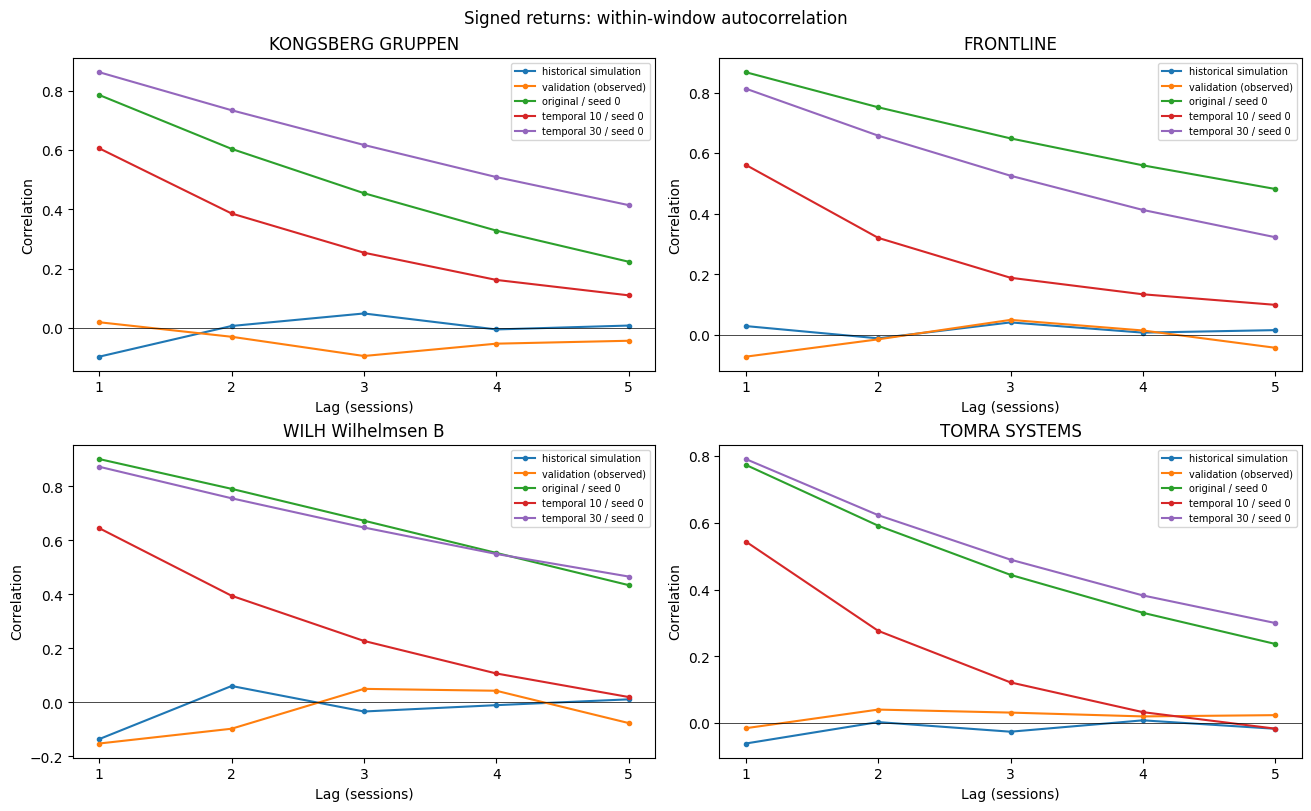

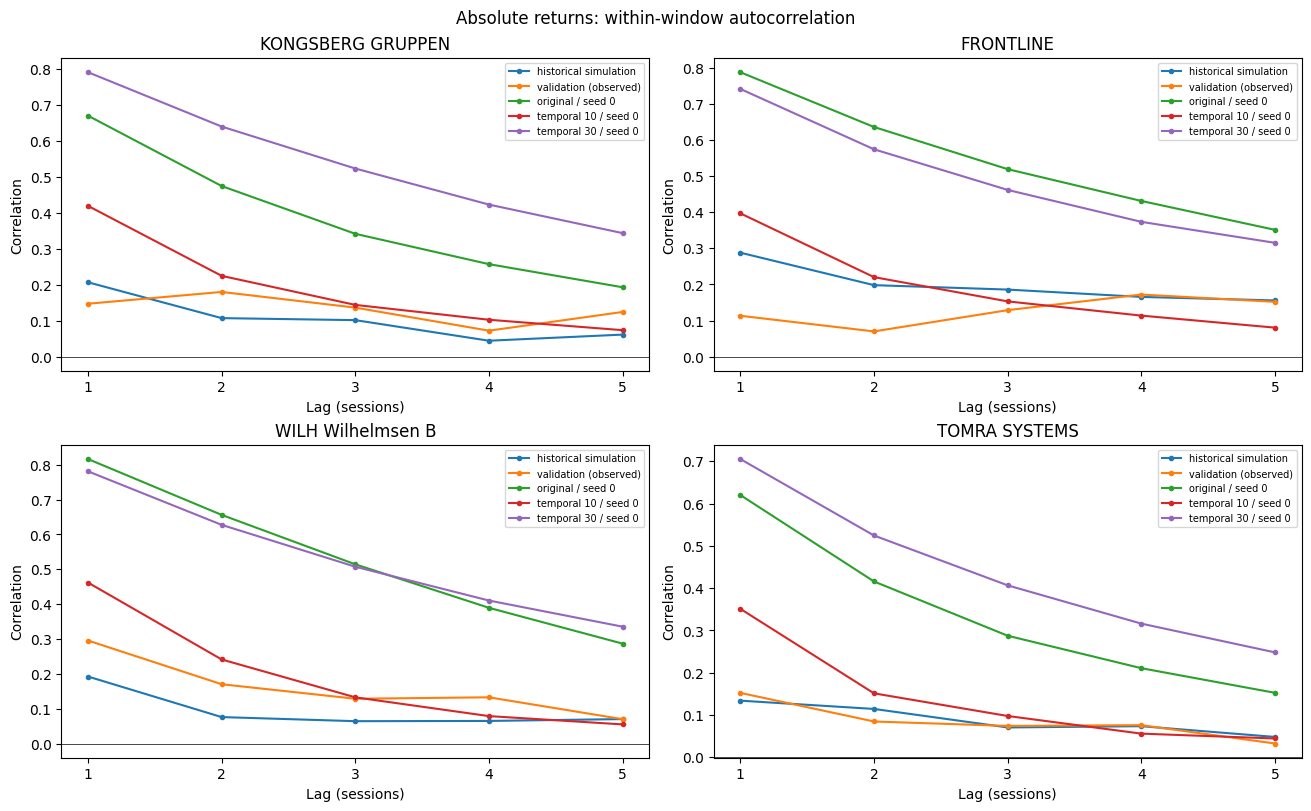

In [7]:
def autocorrelation(paths: np.ndarray, absolute: bool = False) -> pd.DataFrame:
    """Compute pooled within-path lag correlations, preserving path boundaries."""
    values = np.abs(paths) if absolute else paths
    return pd.DataFrame({lag: pd.DataFrame(
        values[:, :-lag].reshape(-1, len(STOCKS)), columns=STOCKS
    ).corrwith(pd.DataFrame(values[:, lag:].reshape(-1, len(STOCKS)), columns=STOCKS))
        for lag in range(1, 6)}).T.rename_axis("lag")


alternating = np.broadcast_to(np.tile([1., -1.], 10)[None, :, None], (3, HORIZON, 4))
np.testing.assert_allclose(autocorrelation(alternating).loc[1], -1)
signed_acf = {name: autocorrelation(paths) for name, paths in datasets.items()}
absolute_acf = {name: autocorrelation(paths, absolute=True) for name, paths in datasets.items()}
display(pd.concat({"signed lag 1": pd.DataFrame({n: t.loc[1] for n, t in signed_acf.items()}).T,
                   "absolute lag 1": pd.DataFrame({n: t.loc[1] for n, t in absolute_acf.items()}).T},
                  names=["metric", "dataset"]).round(3))
for title, tables in [("Signed returns", signed_acf), ("Absolute returns", absolute_acf)]:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for stock, ax in zip(STOCKS, axes.flat):
        for name in plot_names:
            ax.plot(tables[name].index, tables[name][stock], marker=".", label=name)
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set(title=stock, xlabel="Lag (sessions)", ylabel="Correlation", xticks=range(1, 6))
        ax.legend(fontsize=7)
    fig.suptitle(f"{title}: within-window autocorrelation")
    plt.show()
    plt.close(fig)


## Portfolio loss distributions, VaR and ES

All risk values below are percentage losses over **20 sessions**, not annualized
daily figures. Negative VaR is retained if the relevant quantile represents a
gain. The observed validation distribution is a descriptive reference, never
used to set a forecast threshold. `tail_mass` is the empirical probability mass
expressed in numbers of scenarios; fewer than 20 is flagged, matching the
benchmark. ES is particularly sensitive to a small number of extreme losses.


scenarios  mean_loss_pct  std_loss_pct  \
dataset               confidence                                           
historical simulation 0.95             1679        -0.9629        6.2023   
                      0.99             1679        -0.9629        6.2023   
validation (observed) 0.95              709        -3.0303        5.9838   
                      0.99              709        -3.0303        5.9838   
original / seed 0     0.95             1000        -3.2300       23.0036   
                      0.99             1000        -3.2300       23.0036   
original / seed 1     0.95             1000        -2.7302       17.0266   
                      0.99             1000        -2.7302       17.0266   
original / seed 2     0.95             1000        -2.9106        9.2614   
                      0.99             1000        -2.9106        9.2614   
temporal 10 / seed 0  0.95             1000        -0.9410        7.5783   
                      0.99             1000        -0.9410        7.5783   
temporal 10 / seed 1  0.95             1000        -3.2102        8.9976   
                      0.99             1000        -3.2102        8.9976   
temporal 10 / seed 2  0.95             1000        -1.4366        8.7003   
                      0.99             1000        -1.4366        8.7003   
temporal 30 / seed 0  0.95             1000         2.1811        6.9320   
                      0.99             1000         2.1811        6.9320   

                                  var_pct   es_pct  tail_mass  \
dataset               confidence                                
historical simulation 0.95         9.0078  12.6370      83.95   
                      0.99        13.9635  19.6493      16.79   
validation (observed) 0.95         5.7016   8.5656      35.45   
                      0.99        10.3293  11.6574       7.09   
original / seed 0     0.95        20.8618  25.3310      50.00   
                      0.99        27.8960  32.0177      10.00   
original / seed 1     0.95        16.2045  19.8215      50.00   
                      0.99        21.6303  24.9759      10.00   
original / seed 2     0.95        10.8612  15.7153      50.00   
                      0.99        17.7825  22.6009      10.00   
temporal 10 / seed 0  0.95         9.9142  12.8242      50.00   
                      0.99        13.9113  17.6882      10.00   
temporal 10 / seed 1  0.95        10.6280  13.6153      50.00   
                      0.99        14.7659  18.6793      10.00   
temporal 10 / seed 2  0.95        11.1899  15.9443      50.00   
                      0.99        19.4527  23.3515      10.00   
temporal 30 / seed 0  0.95        14.4998  17.5034      50.00   
                      0.99        19.9095  21.0836      10.00   

                                  small_tail_sample  
dataset               confidence                     
historical simulation 0.95                    False  
                      0.99                     True  
validation (observed) 0.95                    False  
                      0.99                     True  
original / seed 0     0.95                    False  
                      0.99                     True  
original / seed 1     0.95                    False  
                      0.99                     True  
original / seed 2     0.95                    False  
                      0.99                     True  
temporal 10 / seed 0  0.95                    False  
                      0.99                     True  
temporal 10 / seed 1  0.95                    False  
                      0.99                     True  
temporal 10 / seed 2  0.95                    False  
                      0.99                     True  
temporal 30 / seed 0  0.95                    False  
                      0.99                     True

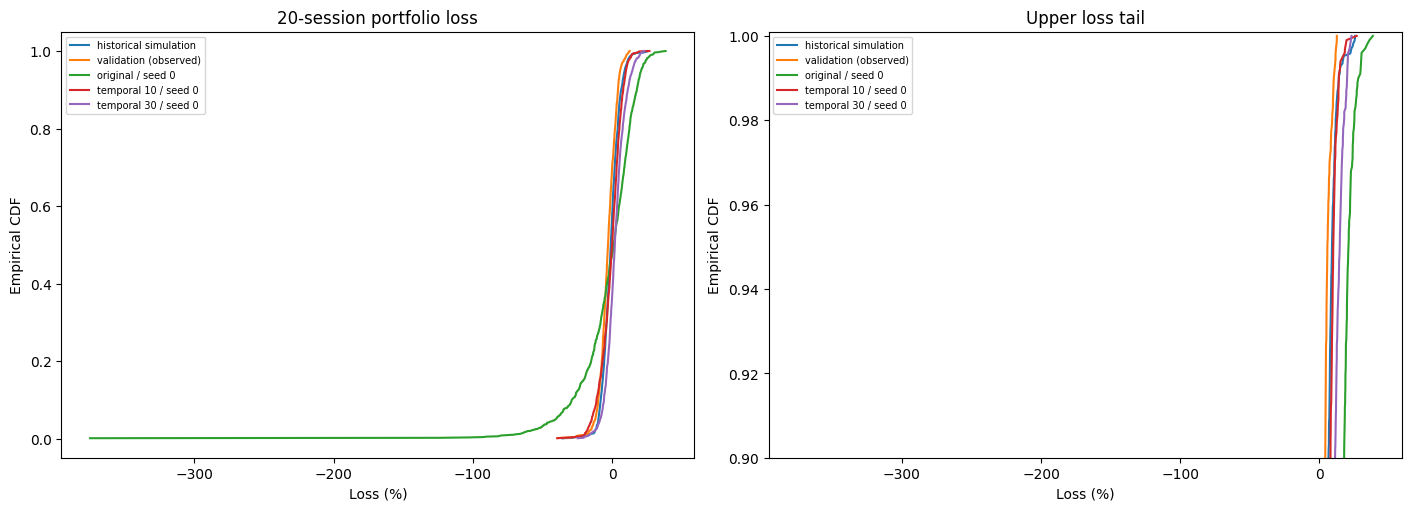

In [8]:
def risk_rows(losses: np.ndarray, name: str) -> list[dict]:
    """Use the benchmark's exact empirical VaR and fractional-mass ES conventions."""
    ordered = np.sort(losses)
    return [{"dataset": name, "confidence": confidence, "scenarios": len(ordered),
             "mean_loss_pct": ordered.mean() * 100, "std_loss_pct": ordered.std(ddof=1) * 100,
             "var_pct": _empirical_var(ordered, confidence) * 100,
             "es_pct": _empirical_es(ordered, confidence) * 100,
             "tail_mass": len(ordered) * (1 - confidence),
             "small_tail_sample": len(ordered) * (1 - confidence) < 20}
            for confidence in CONFIDENCE_LEVELS]


losses = {name: -terminal_returns(paths) for name, paths in datasets.items()}
risk = pd.DataFrame([row for name, values in losses.items()
                     for row in risk_rows(values, name)]).set_index(["dataset", "confidence"])
np.testing.assert_allclose(risk.loc["historical simulation", ["var_pct", "es_pct"]],
                          historical_summary.risk[["var", "es"]].to_numpy() * 100)
assert (risk.es_pct >= risk.var_pct - 1e-12).all()
# Independent fractional-tail fixture: worst 1.5 observations are 0.10 and half of 0.03.
np.testing.assert_allclose(_empirical_es(np.array([-0.02, 0.01, 0.03, 0.10]), 0.625),
                          (0.10 + 0.5 * 0.03) / 1.5)
display(risk.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for name in plot_names:
    ordered = np.sort(losses[name]) * 100
    probability = np.arange(1, len(ordered) + 1) / len(ordered)
    for ax in axes:
        ax.plot(ordered, probability, label=name)
axes[0].set(title="20-session portfolio loss", xlabel="Loss (%)", ylabel="Empirical CDF")
axes[1].set(title="Upper loss tail", xlabel="Loss (%)", ylabel="Empirical CDF", ylim=(0.9, 1.001))
for ax in axes:
    ax.legend(fontsize=7)
plt.show()
plt.close(fig)


## Fixed-distribution validation backtest

For each validation start date, the benchmark forecasts a complete 20-session
target. Targets with missing returns remain in its output and are excluded from
**every method's** scores. All methods use exactly the same eligible dates,
realized losses, and strict breach rule `loss > VaR`. The historical forecast
remains fitted to training data; the generator uses its fixed sample quantile.

Coverage close to $1-c$ alone does not establish a good forecast. Also report
mean quantile (pinball) loss, $\rho_c(L-q)=(c-\mathbf{1}_{L<q})(L-q)$, where
smaller is better for predicting that loss quantile. Values are scaled by 100
for readability. No independence tests, binomial confidence intervals, or
significance claims are made for overlapping targets. The observed average loss
beyond VaR is descriptive and is not by itself a formal ES backtest.


,confidence,horizon_sessions,n_targets,n_estimates,n_comparisons,n_breaches,breach_rate,nominal_tail_probability
0,0.95,20,798,798,709,15,0.021157,0.05
1,0.99,20,798,798,709,0,0.000000,0.01


targets  var_pct   es_pct  breaches  \
dataset               confidence                                        
historical simulation 0.95            709   9.0078  12.6370        15   
                      0.99            709  13.9635  19.6493         0   
original / seed 0     0.95            709  20.8618  25.3310         0   
                      0.99            709  27.8960  32.0177         0   
original / seed 1     0.95            709  16.2045  19.8215         0   
                      0.99            709  21.6303  24.9759         0   
original / seed 2     0.95            709  10.8612  15.7153         6   
                      0.99            709  17.7825  22.6009         0   
temporal 10 / seed 0  0.95            709   9.9142  12.8242        10   
                      0.99            709  13.9113  17.6882         0   
temporal 10 / seed 1  0.95            709  10.6280  13.6153         7   
                      0.99            709  14.7659  18.6793         0   
temporal 10 / seed 2  0.95            709  11.1899  15.9443         5   
                      0.99            709  19.4527  23.3515         0   
temporal 30 / seed 0  0.95            709  14.4998  17.5034         0   
                      0.99            709  19.9095  21.0836         0   

                                  breach_rate_pct  nominal_rate_pct  \
dataset               confidence                                      
historical simulation 0.95                 2.1157               5.0   
                      0.99                 0.0000               1.0   
original / seed 0     0.95                 0.0000               5.0   
                      0.99                 0.0000               1.0   
original / seed 1     0.95                 0.0000               5.0   
                      0.99                 0.0000               1.0   
original / seed 2     0.95                 0.8463               5.0   
                      0.99                 0.0000               1.0   
temporal 10 / seed 0  0.95                 1.4104               5.0   
                      0.99                 0.0000               1.0   
temporal 10 / seed 1  0.95                 0.9873               5.0   
                      0.99                 0.0000               1.0   
temporal 10 / seed 2  0.95                 0.7052               5.0   
                      0.99                 0.0000               1.0   
temporal 30 / seed 0  0.95                 0.0000               5.0   
                      0.99                 0.0000               1.0   

                                  quantile_loss_pct  mean_loss_beyond_var_pct  
dataset               confidence                                               
historical simulation 0.95                   0.6367                   10.6517  
                      0.99                   0.1699                       NaN  
original / seed 0     0.95                   1.1946                       NaN  
                      0.99                   0.3093                       NaN  
original / seed 1     0.95                   0.9617                       NaN  
                      0.99                   0.2466                       NaN  
original / seed 2     0.95                   0.7028                   11.8368  
                      0.99                   0.2081                       NaN  
temporal 10 / seed 0  0.95                   0.6656                   11.2184  
                      0.99                   0.1694                       NaN  
temporal 10 / seed 1  0.95                   0.6932                   11.6745  
                      0.99                   0.1780                       NaN  
temporal 10 / seed 2  0.95                   0.7166                   11.9776  
                      0.99                   0.2248                       NaN  
temporal 30 / seed 0  0.95                   0.8765                       NaN  
                      0.99                   0.2294                       NaN

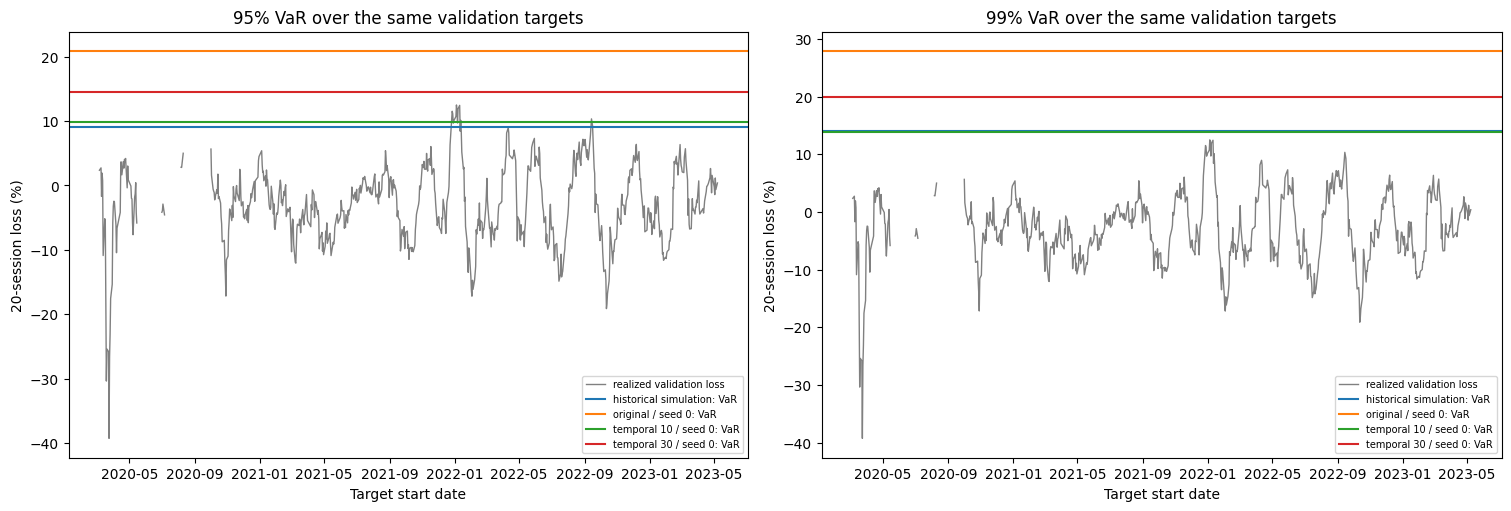

In [9]:
validation_backtest = historical.backtest(returns["validation"])
forecasts = validation_backtest.forecasts
eligible = forecasts.loc[
    forecasts.confidence.eq(CONFIDENCE_LEVELS[0])
    & forecasts.estimate_status.eq("ok") & forecasts.realization_status.eq("ok")
].copy()
validation_dates = window_dates.loc[window_dates.split.eq("validation")].sort_values("window_index")
np.testing.assert_array_equal(eligible.target_start, validation_dates.start_date)
np.testing.assert_array_equal(eligible.target_end, validation_dates.end_date)
np.testing.assert_allclose(eligible.realized_loss, losses["validation (observed)"], rtol=0, atol=1e-14)
assert (forecasts.history_end < forecasts.target_start).all()


def score_forecasts(realized: np.ndarray, method_names: list[str]) -> pd.DataFrame:
    """Compare fixed thresholds on the same complete realized portfolio targets."""
    rows = []
    for name in method_names:
        for confidence in CONFIDENCE_LEVELS:
            estimate = risk.loc[(name, confidence)]
            threshold = estimate.var_pct / 100
            residual = realized - threshold
            breaches = realized > threshold
            rows.append({
                "dataset": name, "confidence": confidence, "targets": len(realized),
                "var_pct": estimate.var_pct, "es_pct": estimate.es_pct,
                "breaches": int(breaches.sum()), "breach_rate_pct": breaches.mean() * 100,
                "nominal_rate_pct": (1 - confidence) * 100,
                "quantile_loss_pct": np.mean((confidence - (residual < 0)) * residual) * 100,
                "mean_loss_beyond_var_pct": realized[breaches].mean() * 100 if breaches.any() else np.nan,
            })
    return pd.DataFrame(rows).set_index(["dataset", "confidence"])


method_names = ["historical simulation", *generated]
validation_scores = score_forecasts(eligible.realized_loss.to_numpy(), method_names)
np.testing.assert_array_equal(validation_scores.loc["historical simulation", "breaches"],
                              validation_backtest.coverage.n_breaches)
display(validation_backtest.coverage)
display(validation_scores.round(4))

plot_targets = forecasts.loc[forecasts.confidence.eq(CONFIDENCE_LEVELS[0])]
fig, axes = plt.subplots(1, len(CONFIDENCE_LEVELS), figsize=(15, 5), constrained_layout=True)
for confidence, ax in zip(CONFIDENCE_LEVELS, np.atleast_1d(axes)):
    ax.plot(plot_targets.target_start, plot_targets.realized_loss * 100, color="0.5", linewidth=1,
            label="realized validation loss")
    for index, name in enumerate(["historical simulation", *representatives]):
        ax.axhline(risk.loc[(name, confidence), "var_pct"], color=f"C{index}",
                   label=f"{name}: VaR")
    ax.set(title=f"{confidence:.0%} VaR over the same validation targets",
           xlabel="Target start date", ylabel="20-session loss (%)")
    ax.legend(fontsize=7)
plt.show()
plt.close(fig)


## Solver sensitivity and variation across fitted seeds

Saved solver checks compare `dt=0.25` with `dt=0.125` using coupled randomness.
The existing `larger_than_mc95` flag is only a review heuristic. Recompute VaR/ES
on those paired samples here because the old check did not examine these exact
risk estimators. A missing fine sample means risk sensitivity is **unavailable**.
Small changes at two resolutions do not prove numerical convergence.

Report each fitted seed before summarizing its range. A range over three seeds,
or a single available seed, is not a confidence interval. Sampling uses the same
seed as the existing inspection; there is no new independent Monte Carlo replicate.


In [10]:
if solver_tables:
    sensitivity = pd.concat(solver_tables, ignore_index=True)
    display(sensitivity.groupby(["group", "seed"]).agg(
        checked_summaries=("metric", "size"),
        flagged_summaries=("larger_than_mc95", "sum"),
        max_abs_change_pp=("difference_pp", lambda s: s.abs().max()),
    ))
solver_risk_rows = []
for name in generated:
    fine_table = (pd.DataFrame(risk_rows(-terminal_returns(fine_generated[name]), name))
                  .set_index("confidence") if name in fine_generated else None)
    for confidence in CONFIDENCE_LEVELS:
        coarse = risk.loc[(name, confidence)]
        solver_risk_rows.append({
            "dataset": name, "confidence": confidence,
            "fine_sample_available": fine_table is not None,
            "var_fine_minus_coarse_pp": (fine_table.loc[confidence, "var_pct"] - coarse.var_pct
                                          if fine_table is not None else np.nan),
            "es_fine_minus_coarse_pp": (fine_table.loc[confidence, "es_pct"] - coarse.es_pct
                                         if fine_table is not None else np.nan),
        })
display(pd.DataFrame(solver_risk_rows).set_index(["dataset", "confidence"]).round(4))

seed_scores = validation_scores.reset_index()
seed_scores = seed_scores.loc[seed_scores.dataset.isin(generated)].copy()
seed_scores["group"] = seed_scores.dataset.map(inventory.group)
seed_ranges = seed_scores.groupby(["group", "confidence"]).agg(
    available_seeds=("dataset", "size"),
    var_min_pct=("var_pct", "min"), var_max_pct=("var_pct", "max"),
    es_min_pct=("es_pct", "min"), es_max_pct=("es_pct", "max"),
    breach_min_pct=("breach_rate_pct", "min"), breach_max_pct=("breach_rate_pct", "max"),
    quantile_loss_min_pct=("quantile_loss_pct", "min"),
    quantile_loss_max_pct=("quantile_loss_pct", "max"),
)
display(seed_ranges.round(4))


checked_summaries  flagged_summaries  max_abs_change_pp
group       seed                                                         
original    0                     9                  0           0.072782
            1                     9                  0           0.079207
            2                     9                  0           0.092838
temporal 10 0                     9                  0           0.185525
            1                     9                  0           0.404300
            2                     9                  0           0.013912

fine_sample_available  \
dataset              confidence                          
original / seed 0    0.95                         True   
                     0.99                         True   
original / seed 1    0.95                         True   
                     0.99                         True   
original / seed 2    0.95                         True   
                     0.99                         True   
temporal 10 / seed 0 0.95                         True   
                     0.99                         True   
temporal 10 / seed 1 0.95                         True   
                     0.99                         True   
temporal 10 / seed 2 0.95                         True   
                     0.99                         True   
temporal 30 / seed 0 0.95                        False   
                     0.99                        False   

                                 var_fine_minus_coarse_pp  \
dataset              confidence                             
original / seed 0    0.95                         -0.0748   
                     0.99                          0.3866   
original / seed 1    0.95                          0.0860   
                     0.99                         -0.1017   
original / seed 2    0.95                          0.0924   
                     0.99                          0.0828   
temporal 10 / seed 0 0.95                          0.1881   
                     0.99                          0.1373   
temporal 10 / seed 1 0.95                          0.4062   
                     0.99                          0.1379   
temporal 10 / seed 2 0.95                         -0.0162   
                     0.99                          0.2424   
temporal 30 / seed 0 0.95                             NaN   
                     0.99                             NaN   

                                 es_fine_minus_coarse_pp  
dataset              confidence                           
original / seed 0    0.95                         0.1638  
                     0.99                         0.2571  
original / seed 1    0.95                        -0.0991  
                     0.99                        -0.1827  
original / seed 2    0.95                         0.0418  
                     0.99                         0.2146  
temporal 10 / seed 0 0.95                         0.0289  
                     0.99                        -0.1206  
temporal 10 / seed 1 0.95                         0.1736  
                     0.99                         0.2811  
temporal 10 / seed 2 0.95                        -0.0090  
                     0.99                        -0.1732  
temporal 30 / seed 0 0.95                            NaN  
                     0.99                            NaN

available_seeds  var_min_pct  var_max_pct  es_min_pct  \
group       confidence                                                          
original    0.95                      3      10.8612      20.8618     15.7153   
            0.99                      3      17.7825      27.8960     22.6009   
temporal 10 0.95                      3       9.9142      11.1899     12.8242   
            0.99                      3      13.9113      19.4527     17.6882   
temporal 30 0.95                      1      14.4998      14.4998     17.5034   
            0.99                      1      19.9095      19.9095     21.0836   

                        es_max_pct  breach_min_pct  breach_max_pct  \
group       confidence                                               
original    0.95           25.3310          0.0000          0.8463   
            0.99           32.0177          0.0000          0.0000   
temporal 10 0.95           15.9443          0.7052          1.4104   
            0.99           23.3515          0.0000          0.0000   
temporal 30 0.95           17.5034          0.0000          0.0000   
            0.99           21.0836          0.0000          0.0000   

                        quantile_loss_min_pct  quantile_loss_max_pct  
group       confidence                                                
original    0.95                       0.7028                 1.1946  
            0.99                       0.2081                 0.3093  
temporal 10 0.95                       0.6656                 0.7166  
            0.99                       0.1694                 0.2248  
temporal 30 0.95                       0.8765                 0.8765  
            0.99                       0.2294                 0.2294

## What do these results support?

The following review is computed from the tables above, so it changes when
inputs or saved runs change. Lower quantile loss supports a better quantile
forecast **on these validation targets**. It does not establish calibrated ES,
better performance on the reserved test set, or superiority across market regimes.
Inspect marginal volatility, signed and absolute dependence, and numerical
sensitivity alongside portfolio risk; a large VaR can simply reflect excessive
generated return persistence.


In [11]:
review = [f"**Validation review:** {len(eligible)} complete, overlapping {HORIZON}-session targets."]
for confidence in CONFIDENCE_LEVELS:
    baseline = validation_scores.loc[("historical simulation", confidence)]
    current = seed_scores.loc[seed_scores.confidence.eq(confidence)]
    better = int((current.quantile_loss_pct < baseline.quantile_loss_pct).sum())
    review.append(
        f"- At {confidence:.0%}, historical simulation has VaR **{baseline.var_pct:.2f}%**, "
        f"ES **{baseline.es_pct:.2f}%**, and **{int(baseline.breaches)}/{int(baseline.targets)}** "
        f"breaches ({baseline.breach_rate_pct:.2f}%; nominal {(1-confidence)*100:.2f}%). "
        f"**{better}/{len(current)}** available model runs have lower validation quantile loss."
    )
review.append("\n**Signed lag-1 persistence (range across the four stocks):**")
for name in plot_names:
    lag_one = signed_acf[name].loc[1]
    review.append(f"- {name}: {lag_one.min():.3f} to {lag_one.max():.3f}.")
observed_upper = signed_acf["validation (observed)"].loc[1].max()
persistent = [name for name in representatives if signed_acf[name].loc[1].min() > observed_upper]
if persistent:
    review.append("\nAll four stocks have higher lag-1 correlation than any observed validation "
                  "stock in these representative runs: " + "; ".join(persistent) + ". "
                  "Generated signed-return persistence remains a substantial mismatch. "
                  "Persistence can affect compounded portfolio tails; these diagnostics "
                  "do not isolate its contribution from volatility and cross-stock dependence.")
missing_fine = [name for name in generated if name not in fine_generated]
if missing_fine:
    review.append("\n**Risk solver sensitivity unavailable:** " + "; ".join(missing_fine) + ".")
review.append(
    f"\nThe {max(CONFIDENCE_LEVELS):.0%} historical tail contains "
    f"{risk.loc[('historical simulation', max(CONFIDENCE_LEVELS)), 'tail_mass']:.2f} "
    "scenario-equivalents, and the scenarios overlap. Treat rare-loss and ES conclusions as provisional. "
    "Validation has influenced checkpoint selection; freeze choices before final test evaluation."
)
display(Markdown("\n".join(review)))


**Validation review:** 709 complete, overlapping 20-session targets.
- At 95%, historical simulation has VaR **9.01%**, ES **12.64%**, and **15/709** breaches (2.12%; nominal 5.00%). **0/7** available model runs have lower validation quantile loss.
- At 99%, historical simulation has VaR **13.96%**, ES **19.65%**, and **0/709** breaches (0.00%; nominal 1.00%). **1/7** available model runs have lower validation quantile loss.

**Signed lag-1 persistence (range across the four stocks):**
- historical simulation: -0.136 to 0.029.
- validation (observed): -0.152 to 0.020.
- original / seed 0: 0.774 to 0.901.
- temporal 10 / seed 0: 0.544 to 0.645.
- temporal 30 / seed 0: 0.791 to 0.873.

All four stocks have higher lag-1 correlation than any observed validation stock in these representative runs: original / seed 0; temporal 10 / seed 0; temporal 30 / seed 0. Generated signed-return persistence remains a substantial mismatch. Persistence can affect compounded portfolio tails; these diagnostics do not isolate its contribution from volatility and cross-stock dependence.

**Risk solver sensitivity unavailable:** temporal 30 / seed 0.

The 99% historical tail contains 16.79 scenario-equivalents, and the scenarios overlap. Treat rare-loss and ES conclusions as provisional. Validation has influenced checkpoint selection; freeze choices before final test evaluation.

## Optional reserved-test evaluation

Leave `EVALUATE_TEST = False` while developing the model. Once model and
evaluation choices are frozen, enable it in setup and rerun the notebook. All
available seeds are evaluated, using the same **training-fitted distributions**
and formulas as above. The historical method stays fixed rather than adding
validation observations: otherwise it would have information unavailable to the
fixed generator. Test observations never enter a fitted forecast distribution.
This opt-in does not certify that numerical sensitivity has been resolved;
review the solver tables before interpreting final risk comparisons.


In [12]:
if EVALUATE_TEST:
    test_backtest = historical.backtest(returns["test"])
    test_targets = test_backtest.forecasts.loc[
        test_backtest.forecasts.confidence.eq(CONFIDENCE_LEVELS[0])
        & test_backtest.forecasts.estimate_status.eq("ok")
        & test_backtest.forecasts.realization_status.eq("ok")
    ]
    test_dates = window_dates.loc[window_dates.split.eq("test")].sort_values("window_index")
    np.testing.assert_array_equal(test_targets.target_start, test_dates.start_date)
    np.testing.assert_array_equal(test_targets.target_end, test_dates.end_date)
    np.testing.assert_allclose(test_targets.realized_loss, -terminal_returns(observed["test"]),
                              rtol=0, atol=1e-14)
    display(score_forecasts(test_targets.realized_loss.to_numpy(), method_names).round(4))
else:
    print("Reserved test returns were not loaded or scored. Validation review only.")


Reserved test returns were not loaded or scored. Validation review only.
